# 04 · Demo: detect animals in an image and a video

The last step: give the trained model a picture (or a video) and see the boxes it draws. This is what the surveillance website does for every frame.

By default the notebook uses a **test image** and a **10-frame demo clip** assembled from test images, so it runs without any extra files.
Point `IMAGE_PATH` / `VIDEO_PATH` at your own files to try them (a webcam index such as `0` also works for `VIDEO_PATH`).

## 1. Find the project and set the parameters

In [1]:
# Find the project root (the folder that contains PROJECT_PLAN.md) and work from there,
# so every path below is relative to the project root no matter where Jupyter was started.
import os, sys
from pathlib import Path

here = Path.cwd().resolve()
for folder in [here, *here.parents]:
    if (folder / "PROJECT_PLAN.md").exists():
        os.chdir(folder)
        break
else:
    raise SystemExit("PROJECT_PLAN.md not found: start Jupyter inside the project folder")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))   # lets us import small helpers from src/ if we need them
print("project root:", ROOT)

project root: /home/upicy/comp_vision


In [2]:
# ---- parameters: change things here ----
FULL_RUN = False
WEIGHTS = "results/weights/best.pt"
CONF = 0.25                      # minimum confidence for a box to be drawn (higher = fewer, surer boxes)
IMGSZ = 640
IMAGE_PATH = None                # None -> first test image. Or e.g. "my_photo.jpg"
VIDEO_PATH = None                # None -> a demo clip built from test images. Or "my_video.mp4", or 0 for a webcam
MAX_FRAMES = 60 if FULL_RUN else 10
OUT_DIR = "notebooks/out"        # annotated results are saved here

import torch
DEVICE = 0 if torch.cuda.is_available() else "cpu"
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
print("weights:", WEIGHTS, "| device:", DEVICE)

weights: results/weights/best.pt | device: 0


## 2. Load the model

In [3]:
import cv2, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ultralytics import YOLO

model = YOLO(WEIGHTS)
NAMES = model.names
print("classes the model knows:", NAMES)

classes the model knows: {0: 'dog', 1: 'goat', 2: 'cow', 3: 'cat', 4: 'sheep'}


## 3. One image
`model.predict` returns, for every box, the class, the confidence (0 to 1) and the corner coordinates. `result.plot()` draws them on the picture.

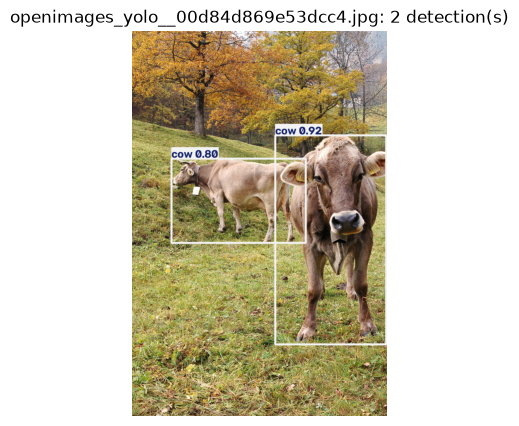

In [4]:
test_images = sorted((ROOT / "data/dataset/images/test").glob("*.jpg"))
image_path = Path(IMAGE_PATH) if IMAGE_PATH else test_images[0]
result = model.predict(str(image_path), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]

annotated = result.plot()                                    # BGR picture with boxes drawn
cv2.imwrite(f"{OUT_DIR}/image_annotated.jpg", annotated)
plt.figure(figsize=(7, 5)); plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{image_path.name}: {len(result.boxes)} detection(s)"); plt.show()

### The detections as a table

In [5]:
table = pd.DataFrame({
    "class": [NAMES[int(c)] for c in result.boxes.cls],
    "confidence": [round(float(s), 3) for s in result.boxes.conf],
    "box x1,y1,x2,y2 (pixels)": [[round(v) for v in b] for b in result.boxes.xyxy.tolist()]})
table

,class,confidence,"box x1,y1,x2,y2 (pixels)"
0,cow,0.92,"[382, 277, 676, 833]"
1,cow,0.80,"[106, 339, 463, 563]"


## 4. Try other confidence thresholds
A low threshold finds more animals but adds false alarms; a high one is stricter but misses animals. The website uses the same idea.

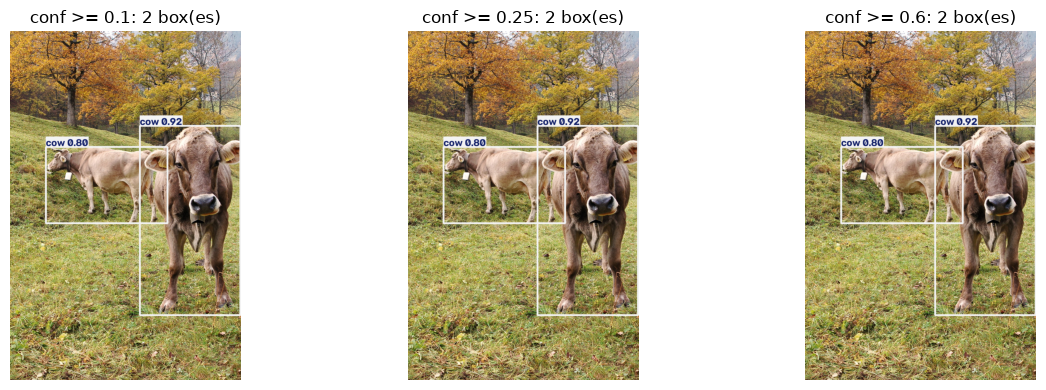

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, conf in zip(axs, [0.10, 0.25, 0.60]):
    r = model.predict(str(image_path), conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"conf >= {conf}: {len(r.boxes)} box(es)")
plt.tight_layout(); plt.show()

## 5. A video
A video is just a list of frames. For each frame we run the model, draw the boxes and write the frame to a new video file.
Without a video of your own, we first build a short clip from test images so the notebook works out of the box.

In [7]:
if VIDEO_PATH is None:                                     # build a small demo clip from test images
    clip = ROOT / OUT_DIR / "demo_input.mp4"
    writer = cv2.VideoWriter(str(clip), cv2.VideoWriter_fourcc(*"mp4v"), 5, (640, 480))
    for k in range(MAX_FRAMES):
        frame = cv2.resize(cv2.imread(str(test_images[k % len(test_images)])), (640, 480))
        writer.write(frame)
    writer.release()
    source = str(clip)
    print("built demo clip:", clip, f"({MAX_FRAMES} frames)")
else:
    source = VIDEO_PATH
    print("using", source)

built demo clip: /home/upicy/comp_vision/notebooks/out/demo_input.mp4 (10 frames)


In [8]:
cap = cv2.VideoCapture(int(source) if str(source).isdigit() else str(source))
assert cap.isOpened(), f"cannot open {source}"
fps_in = cap.get(cv2.CAP_PROP_FPS) or 25.0
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
out_path = f"{OUT_DIR}/video_annotated.mp4"
writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps_in, (w, h))

frames, per_frame, t0 = [], [], time.perf_counter()
while len(per_frame) < MAX_FRAMES:
    ok, frame = cap.read()
    if not ok:
        break
    r = model.predict(frame, conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    shown = r.plot()
    writer.write(shown)
    frames.append(shown)
    per_frame.append({"frame": len(per_frame), "detections": len(r.boxes),
                      "classes": ", ".join(sorted({NAMES[int(c)] for c in r.boxes.cls}))})
cap.release(); writer.release()
elapsed = time.perf_counter() - t0
print(f"{len(per_frame)} frames in {elapsed:.1f}s ({len(per_frame) / elapsed:.1f} frames/s including drawing and writing) -> {out_path}")
pd.DataFrame(per_frame)

10 frames in 0.3s (38.5 frames/s including drawing and writing) -> notebooks/out/video_annotated.mp4


,frame,detections,classes
0,0,2,cow
1,1,1,sheep
2,2,3,goat
3,3,2,"cow, goat"
4,4,4,cow
5,5,1,goat
6,6,3,"cow, goat, sheep"
7,7,3,cow
8,8,2,cow
9,9,0,


### Sample frames from the annotated video

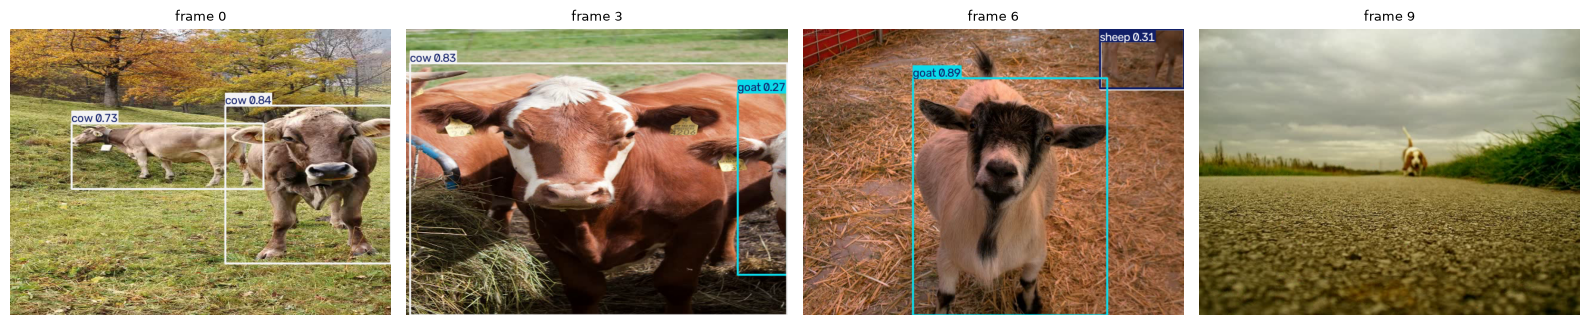

In [9]:
pick = np.linspace(0, len(frames) - 1, min(4, len(frames))).astype(int)
fig, axs = plt.subplots(1, len(pick), figsize=(4 * len(pick), 3.2), squeeze=False)
for ax, k in zip(axs[0], pick):
    ax.imshow(cv2.cvtColor(frames[k], cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"frame {k}", fontsize=9)
plt.tight_layout(); plt.show()

## What to take away
- Detection is one call (`model.predict`); the rest is drawing and saving.
- `conf` trades missed animals against false alarms.
- The full command-line version is `python src/demo.py --source <image|video|0>`; the website runs the same model on live frames.